### Data exploration: PAWS-Wiki

## 1. Dataset Overview

(explicar porque hemos decidido usar este dataset)

In this course we decided to use **PAWS-Wiki (Paraphrase Adversaries from Word Scrambling)**, a dataset designed for binary paraphrase detection. Each instance consists of two sentences labelled according to whether they express the same meaning.

Unlike conventional paraphrase datasets, PAWS contains sentence pairs with high lexical overlap but potentially different meanings, making it particularly challenging for models that rely primarily on word occurrence and frequency.

This makes PAWS suitable for investigating how different text representations and classification architectures capture word order and semantic relationships.

### 1.1. Imports and Setup

The following libraries are used for dataset loading, exploratory data analysis, text tokenisation, and visualisation.

In [16]:
from datasets import load_dataset
import pandas as pd
import numpy as np

from nltk.tokenize import TreebankWordTokenizer
from collections import Counter
from itertools import combinations

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

## 2. Dataset Loading

The PAWS-Wiki dataset is loaded from Hugging Face using the `labeled_final` configuration, which provides manually annotated sentence pairs.

The original training, validation, and test splits are preserved to ensure consistency with the benchmark and prevent information leakage.

### 2.1. Loading the Dataset

In [ ]:
dataset = load_dataset(
    "google-research-datasets/paws",
    "labeled_final"
)

dataset

DatasetDict({
    train: Dataset({
        features: ['id', 'sentence1', 'sentence2', 'label'],
        num_rows: 49401
    })
    test: Dataset({
        features: ['id', 'sentence1', 'sentence2', 'label'],
        num_rows: 8000
    })
    validation: Dataset({
        features: ['id', 'sentence1', 'sentence2', 'label'],
        num_rows: 8000
    })
})

### 2.2. Dataset Structure and Split Sizes

We first examine the structure of the dataset, including the available splits, number of instances, and feature columns.

Each instance corresponds to a sentence pair rather than an individual sentence. The dataset provides three predefined splits, which will be preserved throughout the experiments.

In [ ]:
split_info = pd.DataFrame([
    {
        "Split": split_name,
        "Instances": len(split_data),
        "Columns": ", ".join(split_data.column_names)
    }
    for split_name, split_data in dataset.items()
])

display(split_info)

,Split,Instances,Columns
0,train,49401,"id, sentence1, sentence2, label"
1,test,8000,"id, sentence1, sentence2, label"
2,validation,8000,"id, sentence1, sentence2, label"


### 2.3. Sample Inspection

We inspect a few examples from each class to better understand the paraphrase detection task and the linguistic characteristics of the dataset.

In [15]:
train_df = dataset["train"].to_pandas()

display(train_df.head(5))

,id,sentence1,sentence2,label
0,1,"In Paris , in October 1560 , he secretly met the English ambassador , Nicolas Throckmorton , asking him for a passport to return to England through Scotland .","In October 1560 , he secretly met with the English ambassador , Nicolas Throckmorton , in Paris , and asked him for a passport to return to Scotland through England .",0
1,2,The NBA season of 1975 -- 76 was the 30th season of the National Basketball Association .,The 1975 -- 76 season of the National Basketball Association was the 30th season of the NBA .,1
2,3,"There are also specific discussions , public profile debates and project discussions .","There are also public discussions , profile specific discussions , and project discussions .",0
3,4,"When comparable rates of flow can be maintained , the results are high .",The results are high when comparable flow rates can be maintained .,1
4,5,It is the seat of Zerendi District in Akmola Region .,It is the seat of the district of Zerendi in Akmola region .,1


what means each label

## 3. Class Distribution

Class distribution is an important aspect of a classification dataset, as imbalanced classes may affect model training and evaluation.

We examine the number and proportion of paraphrase (`label = 1`) and non-paraphrase (`label = 0`) instances across the dataset splits. This analysis will help determine whether accuracy is an appropriate evaluation metric and establish a majority-class baseline.

In [17]:
# Count instances of each class in every split
class_counts = pd.DataFrame({
    split: pd.Series(data["label"]).value_counts()
    for split, data in dataset.items()
}).T

# Ensure both classes are present and ordered
class_counts = class_counts.reindex(columns=[0, 1], fill_value=0)

class_counts.columns = ["Non-paraphrase (0)", "Paraphrase (1)"]

# Calculate totals and class proportions
class_counts["Total"] = class_counts[
    ["Non-paraphrase (0)", "Paraphrase (1)"]
].sum(axis=1)

class_counts["Paraphrase (%)"] = (
    100 * class_counts["Paraphrase (1)"] / class_counts["Total"]
).round(2)

display(class_counts)

,Non-paraphrase (0),Paraphrase (1),Total,Paraphrase (%)
train,27572,21829,49401,44.19
test,4464,3536,8000,44.20
validation,4461,3539,8000,44.24


## 4. Sentence Length Analysis

Sentence length is a basic structural property that may influence classification performance. We examine the length of both sentences in each pair and the absolute difference between them.

The analysis aims to determine whether sentence length varies across classes and whether differences in length could provide a superficial signal for paraphrase detection.

### 4.1. Descriptive Statistics

We first compute sentence lengths and summarise their distributions separately for paraphrase and non-paraphrase pairs. Only the training split is used for this exploratory analysis.

In [22]:
# Compute sentence lengths using whitespace tokenisation
length_df = train_df[["label", "sentence1", "sentence2"]].copy()

length_df["len_s1"] = length_df["sentence1"].str.split().str.len()
length_df["len_s2"] = length_df["sentence2"].str.split().str.len()

# Average sentence length and absolute length difference
length_df["mean_length"] = (
    length_df["len_s1"] + length_df["len_s2"]
) / 2

length_df["length_diff"] = (
    length_df["len_s1"] - length_df["len_s2"]
).abs()

# Summary statistics by class
length_summary = length_df.groupby("label").agg(
    mean_length=("mean_length", "mean"),
    median_length=("mean_length", "median"),
    std_length=("mean_length", "std"),
    mean_abs_diff=("length_diff", "mean"),
    median_abs_diff=("length_diff", "median"),
    equal_length_pct=("length_diff", lambda x: 100 * (x == 0).mean())
).round(2)

length_summary.index = ["Non-paraphrase (0)", "Paraphrase (1)"]

display(length_summary)

,mean_length,median_length,std_length,mean_abs_diff,median_abs_diff,equal_length_pct
Non-paraphrase (0),21.35,21.5,5.42,0.99,1.0,36.17
Paraphrase (1),21.32,21.5,5.41,1.02,1.0,33.20


## 5. Lexical Overlap Analysis

PAWS-Wiki was designed to challenge paraphrase detection models by including sentence pairs with high lexical overlap but potentially different meanings. Understanding how lexical similarity varies across classes is therefore important for identifying the limitations of different text representations.

This section examines unigram and bigram overlap, exact Bag-of-Words equality, and their relationship with paraphrase labels. Beyond characterising the dataset, these analyses aim to motivate the selection of feature representations for the classification experiments.

### 5.1. Unigram and Bigram Jaccard Similarity

Jaccard similarity measures the overlap between two sets:

$$
J(A,B) = \frac{|A \cap B|}{|A \cup B|}
$$

Unigram Jaccard measures shared vocabulary regardless of word order, while bigram Jaccard considers adjacent token pairs and therefore captures some local ordering information.

For this exploratory analysis, sentences are lowercased and split on whitespace. This simple tokenisation strategy is used consistently across both measures, independently of the tokenizer selected for the classification models.

In [24]:
def tokenize(text):
    """Simple whitespace tokenisation for exploratory analysis."""
    return text.lower().split()


def get_ngrams(tokens, n=1):
    """Extract consecutive n-grams from a token sequence."""
    return list(zip(*(tokens[i:] for i in range(n))))


def jaccard_similarity(a, b):
    """Compute Jaccard similarity between two collections."""
    a, b = set(a), set(b)

    if not a and not b:
        return 1.0

    return len(a & b) / len(a | b)

In [25]:
# Prepare training pairs
lexical_df = train_df[
    ["sentence1", "sentence2", "label"]
].copy()

# Tokenise each sentence
tokens_s1 = lexical_df["sentence1"].apply(tokenize)
tokens_s2 = lexical_df["sentence2"].apply(tokenize)

# Compute unigram and bigram Jaccard for each pair
lexical_df["unigram_jaccard"] = [
    jaccard_similarity(get_ngrams(t1, 1), get_ngrams(t2, 1))
    for t1, t2 in zip(tokens_s1, tokens_s2)
]

lexical_df["bigram_jaccard"] = [
    jaccard_similarity(get_ngrams(t1, 2), get_ngrams(t2, 2))
    for t1, t2 in zip(tokens_s1, tokens_s2)
]

# Summarise by class
jaccard_summary = lexical_df.groupby("label").agg(
    unigram_mean=("unigram_jaccard", "mean"),
    unigram_median=("unigram_jaccard", "median"),
    unigram_std=("unigram_jaccard", "std"),
    bigram_mean=("bigram_jaccard", "mean"),
    bigram_median=("bigram_jaccard", "median"),
    bigram_std=("bigram_jaccard", "std")
).round(3)

jaccard_summary = jaccard_summary.rename(index={
    0: "Non-paraphrase (0)",
    1: "Paraphrase (1)"
})

display(jaccard_summary)

,unigram_mean,unigram_median,unigram_std,bigram_mean,bigram_median,bigram_std
label,,,,,,
Non-paraphrase (0),0.884,0.882,0.074,0.499,0.500,0.151
Paraphrase (1),0.886,0.882,0.063,0.606,0.607,0.155


### 5.2. Exact Bag-of-Words Equality

Unigram Jaccard similarity ignores token frequencies and word order. To investigate the limitations of unigram-based representations more directly, we examine the proportion of sentence pairs with identical Bag-of-Words representations.

Two sentences have identical Bag-of-Words representations when they contain the same tokens with the same frequencies, regardless of their order.

We also identify pairs with identical token frequencies but different token sequences, where word-order information is necessarily lost.

In [26]:
# Identify pairs with identical token counts
lexical_df["same_bow"] = [
    Counter(t1) == Counter(t2)
    for t1, t2 in zip(tokens_s1, tokens_s2)
]

# Identify pairs with the same BoW but different token order
lexical_df["same_bow_diff_order"] = [
    Counter(t1) == Counter(t2) and t1 != t2
    for t1, t2 in zip(tokens_s1, tokens_s2)
]

# Compute proportions by class
bow_summary = lexical_df.groupby("label").agg(
    total_pairs=("label", "size"),
    same_bow_pct=("same_bow", lambda x: 100 * x.mean()),
    reordered_pairs_pct=(
        "same_bow_diff_order",
        lambda x: 100 * x.mean()
    )
).round(2)

bow_summary = bow_summary.rename(index={
    0: "Non-paraphrase (0)",
    1: "Paraphrase (1)"
})

display(bow_summary)

,total_pairs,same_bow_pct,reordered_pairs_pct
label,,,
Non-paraphrase (0),27572,8.52,8.46
Paraphrase (1),21829,3.94,3.75


In [27]:
# Inspect reordered sentence pairs with identical BoW
examples = lexical_df[
    lexical_df["same_bow_diff_order"]
].groupby("label").head(3)

with pd.option_context("display.max_colwidth", 160):
    display(examples[
        [
            "sentence1",
            "sentence2",
            "label",
            "unigram_jaccard",
            "bigram_jaccard"
        ]
    ])

,sentence1,sentence2,label,unigram_jaccard,bigram_jaccard
8,"The Soviet Union maintained an embassy in Oslo and a consulate in Barentsburg , while Norway maintained a message in Moscow .","The Soviet Union maintained an embassy in Moscow and a consulate in Barentsburg , while Norway maintained a message in Oslo .",0,1.0,0.826087
27,"She worked and lived in Stuttgart , Berlin ( Germany ) and in Vienna ( Austria ) .","She worked and lived in Germany ( Stuttgart , Berlin ) and in Vienna ( Austria ) .",1,1.0,0.619048
44,"Taieri is a former parliamentary electorate in the Otago region of New Zealand , from 1866 to 1911 .","Taieri is a former parliamentary electorate in the New Zealand region of Otago , from 1866 to 1911 .",1,1.0,0.636364
102,It was created by Eddie Mort and Lili Chin and produced by Warner Bros..,It was produced by Eddie Mort and Lili Chin and created by Warner Bros..,0,1.0,0.733333
148,"After the death of her first husband , Katharina Dalton married Tom Dalton , who passed away in 1992 .","After the death of her first husband , Tom Dalton married Katharina Dalton , who passed away in 1992 .",0,1.0,0.809524
275,The Italian church St. Giovanni Bosco is named after St. John Bosco .,The Italian St. Giovanni Bosco Church is named after St. John Bosco .,1,1.0,0.600000


### 5.3. Lexical Overlap and Class Labels

To assess whether lexical overlap provides discriminative information, we compare the distributions of unigram and bigram Jaccard similarity across both classes.

This analysis allows us to investigate whether local word-order information distinguishes paraphrases from non-paraphrases more effectively than unigram overlap alone.

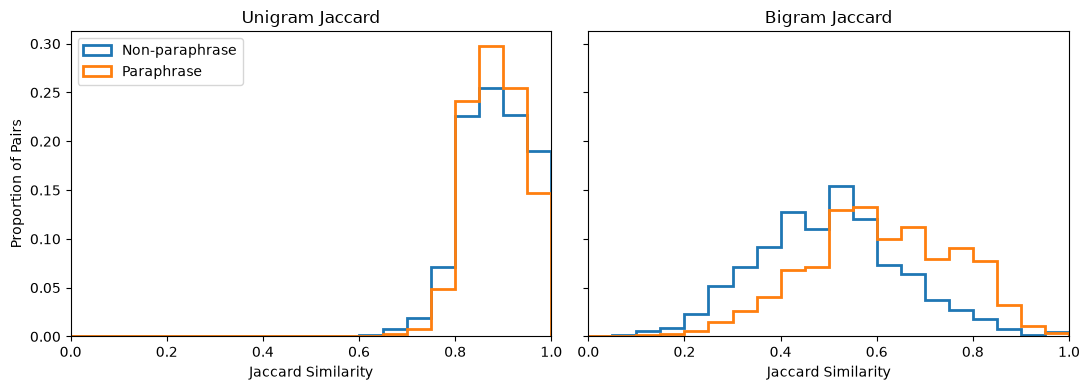

In [28]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(11, 4),
    sharey=True
)

measures = [
    ("unigram_jaccard", "Unigram Jaccard"),
    ("bigram_jaccard", "Bigram Jaccard")
]

for ax, (column, title) in zip(axes, measures):

    for label, name in [
        (0, "Non-paraphrase"),
        (1, "Paraphrase")
    ]:
        values = lexical_df.loc[
            lexical_df["label"] == label,
            column
        ]

        ax.hist(
            values,
            bins=np.linspace(0, 1, 21),
            weights=np.ones(len(values)) / len(values),
            histtype="step",
            linewidth=2,
            label=name
        )

    ax.set_title(title)
    ax.set_xlabel("Jaccard Similarity")
    ax.set_xlim(0, 1)

axes[0].set_ylabel("Proportion of Pairs")
axes[0].legend()

plt.tight_layout()
plt.show()

In [29]:
def paraphrase_rate_by_overlap(df, column):
    bins = np.linspace(0, 1, 6)

    grouped = (
        df.assign(
            overlap_bin=pd.cut(
                df[column],
                bins=bins,
                include_lowest=True
            )
        )
        .groupby("overlap_bin", observed=True)
        .agg(
            n_pairs=("label", "size"),
            paraphrase_rate=("label", "mean")
        )
    )

    grouped["paraphrase_rate"] *= 100

    return grouped.round(2)


print("Unigram Jaccard:")
display(paraphrase_rate_by_overlap(
    lexical_df, "unigram_jaccard"
))

print("Bigram Jaccard:")
display(paraphrase_rate_by_overlap(
    lexical_df, "bigram_jaccard"
))

Unigram Jaccard:


,n_pairs,paraphrase_rate
overlap_bin,,
"(-0.001, 0.2]",1,0.00
"(0.2, 0.4]",6,33.33
"(0.4, 0.6]",69,30.43
"(0.6, 0.8]",5236,34.55
"(0.8, 1.0]",44089,45.36


Bigram Jaccard:


,n_pairs,paraphrase_rate
overlap_bin,,
"(-0.001, 0.2]",640,18.28
"(0.2, 0.4]",9062,22.88
"(0.4, 0.6]",22227,38.68
"(0.6, 0.8]",14310,60.59
"(0.8, 1.0]",3162,74.98


## 6. Vocabulary Characteristics

Vocabulary characteristics provide insight into the lexical diversity and frequency distribution of the dataset. In particular, the presence of rare or unseen words may affect the effectiveness of word-level representations.

This section examines vocabulary size, word frequencies, and out-of-vocabulary (OOV) rates to characterise the lexical properties of PAWS-Wiki before selecting a tokenisation strategy.

### 6.1. Vocabulary Size and Word Frequencies

We analyse the vocabulary of the training split by counting the total number of word occurrences, unique words, and hapax legomena (words appearing exactly once).

Both sentences from each training pair are considered, using the same basic tokenisation procedure as in the previous section.

In [30]:
# Count word occurrences in the training split
word_counts = Counter()

for column in ["sentence1", "sentence2"]:
    for sentence in train_df[column]:
        word_counts.update(tokenize(sentence))

# Vocabulary statistics
total_tokens = sum(word_counts.values())
vocab_size = len(word_counts)
hapax_count = sum(freq == 1 for freq in word_counts.values())

vocab_summary = pd.DataFrame({
    "Statistic": [
        "Total word occurrences",
        "Unique words (vocabulary size)",
        "Hapax legomena",
        "Hapax (% of vocabulary)"
    ],
    "Value": [
        total_tokens,
        vocab_size,
        hapax_count,
        round(100 * hapax_count / vocab_size, 2)
    ]
})

display(vocab_summary)

,Statistic,Value
0,Total word occurrences,2108372.0
1,Unique words (vocabulary size),31542.0
2,Hapax legomena,347.0
3,Hapax (% of vocabulary),1.1


### 6.2. Out-of-Vocabulary Analysis

Out-of-vocabulary (OOV) words are tokens that appear in unseen data but are absent from the training vocabulary.

We measure both the proportion of unique OOV words (type rate) and the proportion of OOV word occurrences (token rate) in the validation split.

These statistics help assess the limitations of a word-level vocabulary when processing previously unseen text.

In [31]:
# Build vocabulary from training data
train_vocab = set(word_counts.keys())

# Tokenise validation sentences
val_tokens = []

for column in ["sentence1", "sentence2"]:
    for sentence in dataset["validation"][column]:
        val_tokens.extend(tokenize(sentence))

# Identify unseen words
val_vocab = set(val_tokens)
oov_words = val_vocab - train_vocab

# Calculate OOV rates
oov_type_rate = 100 * len(oov_words) / len(val_vocab)
oov_token_rate = 100 * sum(
    token not in train_vocab for token in val_tokens
) / len(val_tokens)

oov_summary = pd.DataFrame({
    "Statistic": [
        "Validation vocabulary size",
        "Unseen word types",
        "OOV type rate (%)",
        "OOV token rate (%)"
    ],
    "Value": [
        len(val_vocab),
        len(oov_words),
        round(oov_type_rate, 2),
        round(oov_token_rate, 2)
    ]
})

display(oov_summary)

,Statistic,Value
0,Validation vocabulary size,9169.00
1,Unseen word types,3159.00
2,OOV type rate (%),34.45
3,OOV token rate (%),8.80


## 7. Data Quality and Qualitative Inspection

Before developing the classification models, we examine the dataset for potential quality issues and dependencies between examples.

This analysis focuses on missing values, duplicated sentence pairs, and sentence overlap across dataset splits. We also inspect representative examples to better understand the linguistic phenomena involved in paraphrase detection.

### 7.1. Missing Values and Duplicates

We first check the integrity of the dataset by identifying missing values, empty sentences, and duplicated instances.

Since paraphrase detection is a symmetric task, we also examine whether sentence pairs appear in reversed order and whether identical unordered pairs have conflicting labels.

These checks help identify potential annotation inconsistencies and redundant examples.

In [32]:
# Convert each split to a DataFrame
split_dfs = {
    name: data.to_pandas()
    for name, data in dataset.items()
}

quality_summary = []

for split_name, df in split_dfs.items():

    quality_summary.append({
        "Split": split_name,
        "Missing s1": df["sentence1"].isna().sum(),
        "Missing s2": df["sentence2"].isna().sum(),
        "Missing labels": df["label"].isna().sum(),
        "Empty s1": df["sentence1"].fillna("").str.strip().eq("").sum(),
        "Empty s2": df["sentence2"].fillna("").str.strip().eq("").sum(),
        "Duplicate IDs": df["id"].duplicated().sum()
    })

quality_summary = pd.DataFrame(quality_summary)

display(quality_summary)

,Split,Missing s1,Missing s2,Missing labels,Empty s1,Empty s2,Duplicate IDs
0,train,0,0,0,0,0,0
1,test,0,0,0,0,0,0
2,validation,0,0,0,0,0,0


In [33]:
train_quality = train_df.copy()

# Ordered pairs: (A, B) differs from (B, A)
train_quality["ordered_pair"] = list(zip(
    train_quality["sentence1"],
    train_quality["sentence2"]
))

# Unordered pairs: (A, B) and (B, A) are equivalent
train_quality["unordered_pair"] = [
    tuple(sorted((s1, s2)))
    for s1, s2 in train_quality["ordered_pair"]
]

# Exact duplicates
exact_duplicates = train_quality["ordered_pair"].duplicated().sum()

# Duplicates ignoring sentence order
unordered_duplicates = train_quality["unordered_pair"].duplicated().sum()

# Pairs appearing in both orientations
unique_pairs = set(train_quality["ordered_pair"])

reversed_pairs = sum(
    s1 != s2 and (s2, s1) in unique_pairs
    for s1, s2 in unique_pairs
) // 2

# Conflicting labels for the same unordered pair
conflicting_labels = (
    train_quality.groupby("unordered_pair")["label"]
    .nunique()
    .gt(1)
    .sum()
)

duplicate_summary = pd.DataFrame({
    "Statistic": [
        "Exact duplicate rows (beyond first occurrence)",
        "Unordered duplicate rows (beyond first occurrence)",
        "Distinct reversed pair combinations",
        "Unordered pairs with conflicting labels"
    ],
    "Count": [
        exact_duplicates,
        unordered_duplicates,
        reversed_pairs,
        conflicting_labels
    ]
})

display(duplicate_summary)

,Statistic,Count
0,Exact duplicate rows (beyond first occurrence),52
1,Unordered duplicate rows (beyond first occurrence),96
2,Distinct reversed pair combinations,44
3,Unordered pairs with conflicting labels,31


### 7.2. Sentence Overlap Across Splits

Sentence pairs may share individual sentences, even when the complete pairs are different.

We examine whether sentences and sentence pairs appear across the predefined dataset splits. Such overlap can introduce dependencies between training and evaluation examples, potentially affecting the interpretation of model performance.

The analysis distinguishes shared individual sentences from repeated sentence pairs. No modifications to the official splits are made at this stage.

In [34]:
# Unique sentences in the training split
train_sentences = (
    set(train_df["sentence1"])
    | set(train_df["sentence2"])
)

# Training sentence pairs
train_ordered_pairs = set(train_quality["ordered_pair"])
train_unordered_pairs = set(train_quality["unordered_pair"])

overlap_results = []

for split_name in ["validation", "test"]:

    df = split_dfs[split_name]

    # Unique sentences
    split_sentences = (
        set(df["sentence1"])
        | set(df["sentence2"])
    )

    shared_sentences = train_sentences & split_sentences

    # Sentence pairs
    ordered_pairs = list(zip(df["sentence1"], df["sentence2"]))

    unordered_pairs = [
        tuple(sorted(pair))
        for pair in ordered_pairs
    ]

    # Examples sharing at least one sentence with training
    shared_instances = sum(
        s1 in train_sentences or s2 in train_sentences
        for s1, s2 in ordered_pairs
    )

    overlap_results.append({
        "Split": split_name,
        "Shared unique sentences": len(shared_sentences),
        "Shared sentences (%)": round(
            100 * len(shared_sentences) / len(split_sentences), 2
        ),
        "Pairs sharing a sentence (%)": round(
            100 * shared_instances / len(df), 2
        ),
        "Repeated ordered pairs": sum(
            pair in train_ordered_pairs
            for pair in ordered_pairs
        ),
        "Repeated unordered pairs": sum(
            pair in train_unordered_pairs
            for pair in unordered_pairs
        )
    })

overlap_summary = pd.DataFrame(overlap_results)

display(overlap_summary)

,Split,Shared unique sentences,Shared sentences (%),Pairs sharing a sentence (%),Repeated ordered pairs,Repeated unordered pairs
0,validation,0,0.0,0.0,0,0
1,test,0,0.0,0.0,0,0


### 7.3. Qualitative Inspection

Finally, we inspect representative sentence pairs from both classes to better understand the linguistic challenges present in PAWS-Wiki.

For each class, we select five random examples and five examples with high unigram overlap. This allows us to examine both general sentence-pair characteristics and cases where lexical similarity may be misleading.

Particular attention is given to word reordering, changes in semantic roles, and differences between lexical similarity and semantic equivalence.

In [35]:
qualitative_examples = []

for label in [0, 1]:

    class_df = lexical_df[
        lexical_df["label"] == label
    ]

    # High-overlap examples: sample from the top 10%
    threshold = class_df["unigram_jaccard"].quantile(0.90)

    high_overlap = class_df[
        class_df["unigram_jaccard"] >= threshold
    ].sample(n=5, random_state=42)

    # Random examples, excluding those already selected
    remaining = class_df.drop(high_overlap.index)

    random_examples = remaining.sample(
        n=5,
        random_state=42
    )

    selected = pd.concat([
        random_examples.assign(selection="Random"),
        high_overlap.assign(selection="High overlap")
    ])

    qualitative_examples.append(selected)

qualitative_examples = pd.concat(qualitative_examples)

with pd.option_context("display.max_colwidth", 150):
    display(qualitative_examples[
        [
            "sentence1",
            "sentence2",
            "label",
            "unigram_jaccard",
            "bigram_jaccard",
            "selection"
        ]
    ])

,sentence1,sentence2,label,unigram_jaccard,bigram_jaccard,selection
20233,Antony died on 6 November 1620 and was buried on November 7 in the church of Carew .,Carew died on 6 November 1620 and was buried in Antony church on 7 November .,0,0.875000,0.280000,Random
17447,"Thomas Johansson won against Renzo Furlan in the finals with 6 -- 3 , 6 -- 4 .","Renzo Furlan won in the final 6 -- 3 , 6 -- 4 against Thomas Johansson .",0,0.823529,0.347826,Random
36971,"The average net salary of a Croatian worker in January 2017 was 5,895 HRK per month , and the average gross salary was 7,911 HRK per month .","The average gross content of a Croatian worker was 5,895 HRK per month in January 2017 , and the average net content was 7,911 HRK per month .",0,0.909091,0.548387,Random
28578,"Peter Myers is the father of Don Myers in the novel , as opposed to Michael Myers and Judith Myers in the film .","Don Myers is the father of Michael Myers and Judith Myers in the novel , in contrast to Peter Myers in the Film .",0,0.842105,0.615385,Random
32868,"Javier Moracho Torrente ( born August 18 , 1957 in Spain ) is a former Monzón Huesca hurdler .","Javier Moracho Torrente ( born August 18 , 1957 in Monzón , Huesca ) is a retired hurdler from Spain .",0,0.857143,0.407407,Random
1944,49.9 % were male and 50.1 % female .,49.9 % were female and 50.1 % were male .,0,1.000000,0.454545,High overlap
23298,"Is a short book by Karla Kuskin , first published illustrations by Virginia Cary Hudson in 1962 .","Is a short book by Virginia Cary Hudson , first published illustrations by Karla Kuskin in 1962 .",0,1.000000,0.789474,High overlap
3096,The Ceapa is a tributary of the Titimoiu River in Romania .,The River Titimoiu is a tributary of the Ceapa River in Romania .,0,1.000000,0.533333,High overlap
12657,"Wooster Victory , first operated under its original name , was then renamed Castelverde , while Vassar Victory was immediately renamed Castelbianco .","Wooster Victory , immediately operated under its original name , first was renamed Castelverde , while Vassar Victory was then renamed Castelbianco .",0,1.000000,0.692308,High overlap
3938,"The magazine was located in London , but was published by Gerald Duckworth and Company in Paris .","The magazine was located in Paris , but was published by Gerald Duckworth and Company in London .",0,1.000000,0.789474,High overlap
